# Step 4. Cluster profiles (k-means) and spatial hotspots (DBSCAN).

* k-means on three standardized measures: anemia, open defecation, malaria.
    Number of profiles chosen with the elbow method (and silhouette as a check).
  * DBSCAN on the locations of clusters in the "all three high" profile,
    using great-circle (haversine) distance, to find spatial hotspots.

Input : data/private/clusters_features.parquet
Output: data/private/clusters_profiles.parquet          (private)
        data/public/kmeans_elbow.csv, kmeans_profiles.csv, dbscan_summary.csv (public)

*Run on the author's computer. The DHS data are private, so the outputs shown here are summaries only (no cluster locations or survey records).*

In [1]:
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
from config import PRIVATE, PUBLIC

In [2]:
K = 5                     # elbow bends around 4-5; silhouette is highest at 5 -> 5 profiles
EPS_KM, MIN_SAMPLES = 50, 15
MEASURES = ["anemia_pct", "od_pct", "pfpr"]

In [3]:
cl = pd.read_parquet(PRIVATE / "clusters_features.parquet")
# MAP leaves malaria-free areas (e.g. Lesotho, Eswatini, highlands) blank -> treat as 0 % prevalence
cl["pfpr_missing"] = cl.pfpr.isna().astype(int)
cl["pfpr"] = cl.pfpr.fillna(0)
cl = cl.dropna(subset=MEASURES).reset_index(drop=True)
X = StandardScaler().fit_transform(cl[MEASURES])

## Elbow

In [4]:
rng = np.random.default_rng(0)
sample = rng.choice(len(X), size=min(8000, len(X)), replace=False)
rows = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X)
    sil = silhouette_score(X[sample], km.labels_[sample]) if k > 1 else np.nan
    rows.append({"k": k, "inertia": km.inertia_, "silhouette": sil})
elbow = pd.DataFrame(rows)
elbow.to_csv(PUBLIC / "kmeans_elbow.csv", index=False)
print(elbow.round(3).to_string(index=False))

 k   inertia  silhouette
 1 66291.000         NaN
 2 43696.083       0.333
 3 31512.846       0.335
 4 24330.701       0.328
 5 18853.094       0.355
 6 16738.027       0.353
 7 14939.232       0.346
 8 13246.656       0.313
 9 12230.847       0.303
10 11268.609       0.301


## Final k-means

In [5]:
km = KMeans(n_clusters=K, n_init=25, random_state=0).fit(X)
cl["profile_raw"] = km.labels_
cent = cl.groupby("profile_raw")[MEASURES].mean()
z = (cent - cl[MEASURES].mean()) / cl[MEASURES].std()

In [6]:
def name(row):
    hi = [lbl for lbl, col in [("anemia", "anemia_pct"), ("open defecation", "od_pct"), ("malaria", "pfpr")]
          if row[col] > 0.25]
    if len(hi) == 3:
        return "All three high"
    if not hi:
        return "All three low"
    return "High " + " + ".join(hi)

In [7]:
names = z.apply(name, axis=1)
# make names unique if two profiles share a label
for n, idx in names.groupby(names).groups.items():
    if len(idx) > 1:
        for j, i in enumerate(sorted(idx, key=lambda i: -z.loc[i].sum())):
            names[i] = f"{n} ({'stronger' if j == 0 else 'weaker'})"
order = z.sum(axis=1).sort_values(ascending=False).index          # 1 = highest burden
pid = {raw: i + 1 for i, raw in enumerate(order)}
cl["profile"] = cl.profile_raw.map(pid)
cl["profile_name"] = cl.profile_raw.map(names)

In [8]:
prof = (cl.groupby(["profile", "profile_name"])
          .agg(n_clusters=("anemia_pct", "size"), n_children=("n_children", "sum"),
               anemia_pct=("anemia_pct", "mean"), od_pct=("od_pct", "mean"), pfpr=("pfpr", "mean"),
               rain_3mo_z=("rain_3mo_z", "mean"), wealth=("wealth", "mean"),
               mom_secondary_pct=("mom_secondary_pct", "mean"), urban_pct=("urban", "mean"))
          .reset_index())
prof["urban_pct"] *= 100
prof["share_pct"] = 100 * prof.n_clusters / prof.n_clusters.sum()
prof.round(2).to_csv(PUBLIC / "kmeans_profiles.csv", index=False)
print(prof.round(1).to_string(index=False))

 profile          profile_name  n_clusters  n_children  anemia_pct  od_pct  pfpr  rain_3mo_z  wealth  mom_secondary_pct  urban_pct  share_pct
       1        All three high        2285       23879        85.3    82.6  53.5         0.3     2.1                5.9        9.9       10.3
       2 High anemia + malaria        4547       43001        77.4    10.5  46.5         0.0     2.8               16.6       22.9       20.6
       3  High open defecation        3238       39620        61.5    79.9  11.5         0.0     2.0               14.4        7.8       14.7
       4           High anemia        6299       74697        73.6     8.4  10.5        -0.0     3.2               26.5       41.3       28.5
       5         All three low        5728       55625        33.6     7.2  10.5        -0.0     3.3               30.2       37.8       25.9


## Dbscan hotspots within the highest-burden profile

In [9]:
top = cl.profile == 1
coords = np.radians(cl.loc[top, ["lat", "lon"]].to_numpy())
db = DBSCAN(eps=EPS_KM / 6371.0, min_samples=MIN_SAMPLES, metric="haversine",
            algorithm="ball_tree").fit(coords)
cl["hotspot"] = -1
cl.loc[top, "hotspot"] = db.labels_
cl["in_hotspot"] = (cl.hotspot >= 0).astype(int)

In [10]:
hs = (cl[cl.hotspot >= 0].groupby("hotspot")
        .agg(n_clusters=("lat", "size"), countries=("country", lambda s: ", ".join(sorted(s.unique()))),
             anemia_pct=("anemia_pct", "mean"), od_pct=("od_pct", "mean"), pfpr=("pfpr", "mean"))
        .sort_values("n_clusters", ascending=False).reset_index(drop=True))
hs.index = hs.index + 1
hs.index.name = "hotspot"
hs.round(1).to_csv(PUBLIC / "dbscan_summary.csv")
print(f"\nDBSCAN: {top.sum():,} clusters in profile 1 -> {len(hs)} hotspots, "
      f"{cl.in_hotspot.sum():,} clusters in a hotspot, {(db.labels_ == -1).sum():,} scattered")
print(hs.head(15).round(1).to_string())


DBSCAN: 2,285 clusters in profile 1 -> 7 hotspots, 1,578 clusters in a hotspot, 707 scattered
         n_clusters                                        countries  anemia_pct  od_pct  pfpr
hotspot                                                                                       
1              1177  Benin, Burkina Faso, Ghana, Mali, Nigeria, Togo        85.9    87.7  57.4
2               168                    Guinea, Liberia, Sierra Leone        81.2    74.4  46.3
3                95                               Burkina Faso, Mali        91.1    74.2  62.6
4                49                            Benin, Niger, Nigeria        82.4    82.5  44.1
5                36                                           Guinea        78.8    73.0  41.8
6                32                               Burkina Faso, Mali        95.7    71.9  68.5
7                21                                          Liberia        68.9    81.4  54.4


## Sensitivity: how do hotspots change with the search radius?

In [11]:
sens = []
for eps in (25, 50, 75, 100):
    lab = DBSCAN(eps=eps / 6371.0, min_samples=MIN_SAMPLES, metric="haversine",
                 algorithm="ball_tree").fit(coords).labels_
    cl[f"hot_{eps}"] = 0
    cl.loc[top, f"hot_{eps}"] = (lab >= 0).astype(int)
    sens.append({"eps_km": eps, "n_hotspots": int(lab.max() + 1), "clusters_in_hotspots": int((lab >= 0).sum()),
                 "share_pct": round(100 * (lab >= 0).mean(), 1)})
pd.DataFrame(sens).to_csv(PUBLIC / "dbscan_sensitivity.csv", index=False)
print(pd.DataFrame(sens).to_string(index=False))

 eps_km  n_hotspots  clusters_in_hotspots  share_pct
     25          11                   483       21.1
     50           7                  1578       69.1
     75           6                  1952       85.4
    100           5                  2018       88.3


In [12]:
cl.drop(columns="profile_raw").to_parquet(PRIVATE / "clusters_profiles.parquet", index=False)

## Elbow and silhouette

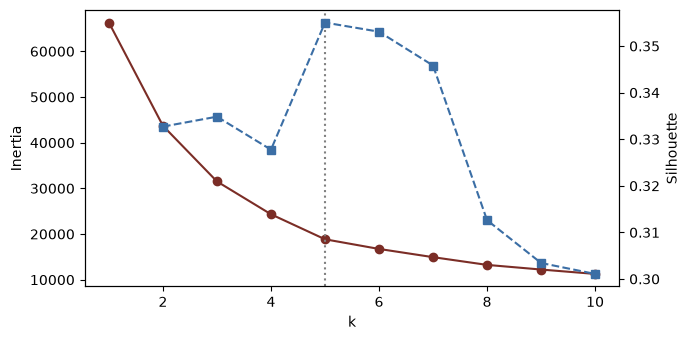

In [13]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(elbow.k, elbow.inertia, "o-", color="#7b2d26"); ax.set(xlabel="k", ylabel="Inertia")
ax2 = ax.twinx(); ax2.plot(elbow.k, elbow.silhouette, "s--", color="#3b6ea5"); ax2.set_ylabel("Silhouette")
ax.axvline(K, color="grey", ls=":")
plt.tight_layout(); plt.show()

## Profile averages

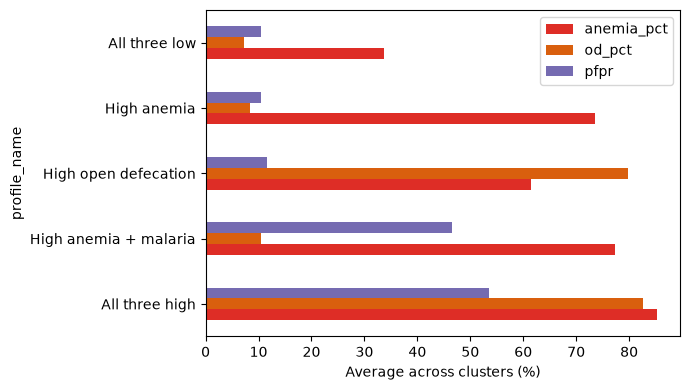

In [14]:
prof.set_index("profile_name")[["anemia_pct", "od_pct", "pfpr"]].plot.barh(
    figsize=(7, 4), color=["#de2d26", "#d95f0e", "#756bb1"])
plt.xlabel("Average across clusters (%)"); plt.tight_layout(); plt.show()